# Compensation-Aware Facial Palsy Assessment (ParFace) v3
Measures palsy-side movement, healthy-side compensation and asymmetry from face video frames, and tests whether compensation adds information beyond symmetry alone.

**Run order:** cells top to bottom. After the install cell, do **Runtime > Restart session** once. The label section writes a `meta.csv` template: fill in the sides from the dataset documentation or a clinician, then run the validation cell.

**What changed from v1**
- Fixed the undefined `meta` variable and removed the placeholder / made-up label cells.
- Controls no longer get a biased asymmetry: the model uses the **unsigned** asymmetry `aasym_*` (signed `asym_*` is kept for patient status only).
- Added a **mirrored-video switch** (swapped sides would silently invert healthy and palsy).
- Features now map to muscle regions: brow (frontalis), eye (orbicularis oculi), mouth up (zygomaticus), mouth down (depressor anguli oris), mouth lateral (risorius/zygomaticus).
- Added **longitudinal logic** (needs a `visit` column): change vs. previous visit and vs. the patient's best visit, with all four status states from the proposal.
- Added **repeat-video reliability (ICC)**, a patient-level **bootstrap** for symmetry vs. symmetry + compensation, and a plain-language per-video report.

**Limits (keep these in any write-up)**
- Landmark measures are proxies for muscle activity, not muscle measurements. Platysma is not measurable from frontal video.
- Without control videos the norm is circular and provisional. It is not a healthy norm.
- Synkinesis and movement timing are not modelled.
- Research prototype, not a diagnostic or dosing tool.

**v4 changes**
- Cell 6: incremental feature cache, so new videos (e.g. controls) are processed without rerunning everything.
- Cell 11: loads `meta.csv` itself (no undefined `meta`), merges optional `author_labels.csv`, and never guesses sides.
- Cell 13: videos without a valid `palsy_side` are excluded instead of being treated as palsy cases.


In [1]:
!pip -q install -U mediapipe opencv-python-headless
!wget -q -O face_landmarker.task https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task
import mediapipe as mp
print('mediapipe', mp.__version__)

mediapipe 1.2.3


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
from IPython.display import display

ZIP    = Path('/content/drive/MyDrive/ParFace.zip')
ROOT   = Path('/content/ParFace')
OUT    = Path('/content/drive/MyDrive/ParFace_outputs'); OUT.mkdir(exist_ok=True)
META   = OUT / 'meta.csv'
CACHE  = OUT / 'frame_features.csv'     # same format as v1, so an old cache can be reused
STRIDE = 3
MAX_FRAMES_PER_VIDEO = 300
YAW_MAX = 0.12
MIRRORED = False   # set True if frames are selfie-mirrored (subject's right shown on image RIGHT)

if not ROOT.exists() or not any(ROOT.rglob('*.png')):
    ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(ZIP) as z: z.extractall(ROOT)

frames = sorted(p for p in ROOT.rglob('*')
                if p.suffix.lower() in ('.png', '.jpg', '.jpeg') and p.parent.name.startswith('Video'))
idx = pd.DataFrame([dict(video_id=p.parent.name, path=str(p)) for p in frames])
assert len(idx) > 0, f'No frames under {ROOT}'
print(len(idx), 'frames |', idx.video_id.nunique(), 'videos')
print(sorted(idx.video_id.unique()))

Mounted at /content/drive
4159 frames | 28 videos
['Video1', 'Video10', 'Video11', 'Video12', 'Video13', 'Video14', 'Video15', 'Video16', 'Video17', 'Video18', 'Video19', 'Video1a', 'Video1b', 'Video2', 'Video20', 'Video21', 'Video22', 'Video23', 'Video24', 'Video24a', 'Video25', 'Video3', 'Video4', 'Video5', 'Video6', 'Video7', 'Video8', 'Video9']


### Optional: check whether ParFace already ships labels or landmark files
Earlier exploration showed a `MAL3D` folder with `.txt` files. If the dataset includes palsy side or grade, use it instead of guessing labels.

In [3]:
from collections import Counter
print(Counter(p.suffix.lower() for p in ROOT.rglob('*') if p.is_file()))
others = [p.relative_to(ROOT) for p in ROOT.rglob('*')
          if p.is_file() and p.suffix.lower() not in {'.png', '.jpg', '.jpeg'} and p.parent.name != 'MAL3D']
print(len(others), 'non-image files outside MAL3D:'); [print(' ', p) for p in others[:30]]

Counter({'.png': 4159, '.txt': 1350, '.c2b': 3, '': 1, '.ljson': 1})
5 non-image files outside MAL3D:
  ParFace/List
  ParFace/palsy_annotations.ljson
  ParFace/Video25/Video25.c2b
  ParFace/Video24/Video24.c2b
  ParFace/Video24a/Video24a.c2b


[None, None, None, None, None]

### Landmarks and per-frame features (cached)

frames with a detected face: 1384 of 4159
count    28.000000
mean     40.750000
std      11.180754
min       1.000000
25%      38.750000
50%      42.500000
75%      50.000000
max      50.000000
dtype: float64


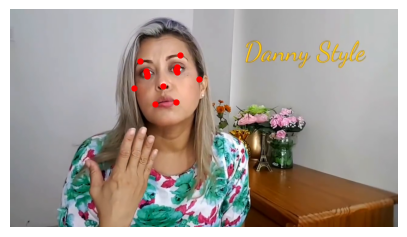

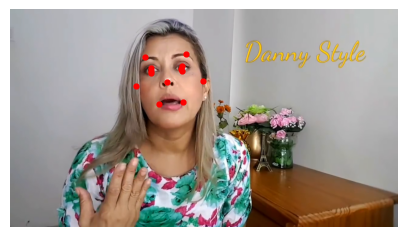

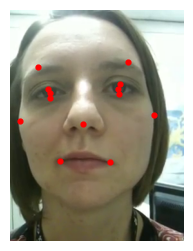

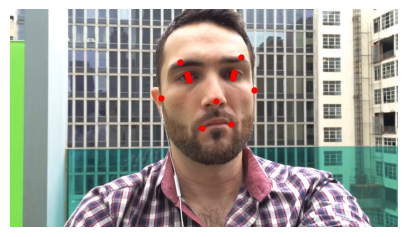

In [4]:
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

detector = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path='face_landmarker.task'),
    num_faces=1, min_face_detection_confidence=0.5))

def landmarks(path):
    img = cv2.imread(str(path))
    if img is None: return None
    h, w = img.shape[:2]
    rgb = np.ascontiguousarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    r = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not r.face_landmarks: return None
    return np.array([[p.x * w, p.y * h] for p in r.face_landmarks[0]])   # 478 points incl. irises

def normalize(pts):
    # origin = pupil midpoint, pupil line rotated horizontal, scale = inter-pupillary distance
    pr, pl = pts[468], pts[473]
    c, ipd = (pr + pl) / 2, np.linalg.norm(pl - pr)
    a = -np.arctan2(pl[1] - pr[1], pl[0] - pr[0])
    R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    return ((pts - c) @ R.T) / ipd

# subject's right side appears on image-left (negative x); y points down
S = {'R': dict(corner=61,  brow=105, up=159, lo=145, iris=468, sg=-1),
     'L': dict(corner=291, brow=334, up=386, lo=374, iris=473, sg=+1)}

def frame_feats(path):
    pts = landmarks(path)
    if pts is None: return None
    yaw = (pts[1][0] - (pts[234][0] + pts[454][0]) / 2) / abs(pts[454][0] - pts[234][0])
    n = normalize(pts)
    f = dict(yaw=yaw)
    for s, d in S.items():
        f[f'mouth_up_{s}']  = -(n[d['corner']][1] - n[1][1])      # corner height vs nose tip (+ = raised)
        f[f'mouth_out_{s}'] = d['sg'] * (n[d['corner']][0] - n[1][0])  # lateral corner position (+ = outward)
        f[f'brow_{s}']      = n[d['iris']][1] - n[d['brow']][1]   # brow-to-pupil distance (+ = brow raised)
        f[f'eye_{s}']       = abs(n[d['up']][1] - n[d['lo']][1])  # palpebral aperture
    return f

def extract(vids):
    out = []
    for vid, g in tqdm(idx[idx.video_id.isin(vids)].groupby('video_id')):
        g = g.sort_values('path').iloc[::STRIDE].head(MAX_FRAMES_PER_VIDEO)
        for p in g.path:
            f = frame_feats(p)
            if f: out.append(dict(video_id=vid, path=p, **f))
    return out

# incremental cache: only videos missing from the cache are processed, so new videos
# (e.g. control videos named VideoC01, VideoC02, ...) can be added without a full rerun
if CACHE.exists():
    ff = pd.read_csv(CACHE)
    missing = sorted(set(idx.video_id) - set(ff.video_id))
    if missing:
        print('processing new videos:', missing)
        new_rows = extract(missing)
        if new_rows:
            ff = pd.concat([ff, pd.DataFrame(new_rows)], ignore_index=True); ff.to_csv(CACHE, index=False)
else:
    ff = pd.DataFrame(extract(sorted(idx.video_id.unique()))); ff.to_csv(CACHE, index=False)

print('frames with a detected face:', len(ff), 'of', len(idx))
ff = ff[ff.yaw.abs() < YAW_MAX]
print(ff.groupby('video_id').size().describe())

def show(path):
    pts = landmarks(path); img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(5, 3)); plt.imshow(img)
    for i in [468, 473, 61, 291, 105, 334, 159, 145, 386, 374, 1, 234, 454]:
        plt.scatter(*pts[i], s=12, c='r')
    plt.axis('off'); plt.show()
for p in ff.sample(min(4, len(ff)), random_state=0).path: show(p)

### Labels
Open `meta.csv` on Drive and fill: `patient_id` (same ID for the same person across videos), `palsy_side` (`L`, `R`, or `none` for a healthy control), optional `grade` (numeric, e.g. House-Brackmann 1-6 or Sunnybrook composite) and optional `visit` (number or date order per patient, for longitudinal tracking).

Check the side convention against the dataset documentation. `L` means the **subject's** left.

In [5]:
if not META.exists():
    pd.DataFrame({'video_id': sorted(idx.video_id.unique()),
                  'patient_id': '', 'palsy_side': '', 'grade': '', 'visit': ''}).to_csv(META, index=False)
    print('Template written to', META, '- fill it in, then run the next cell.')
else:
    print('meta.csv already exists:', META)

meta.csv already exists: /content/drive/MyDrive/ParFace_outputs/meta.csv


### Optional: side-check helper (CHECK ONLY)
Shows a peak-smile frame per unlabelled video and which side moves less. **Do not copy these suggestions into `meta.csv`**: asymmetry is measured from the same movement, so labels taken from it would make the results circular. Take the sides from the dataset documentation or a clinician.

24 videos without a valid palsy_side


,video_id,n_frames,R_move,L_move,asym_RL,less_mobile_side,weak_signal,note
0,Video10,50,0.311,0.221,0.170,L,False,NaN
1,Video11,29,0.148,0.210,-0.173,R,False,NaN
2,Video12,41,0.443,0.283,0.220,L,False,NaN
3,Video13,28,0.139,0.255,-0.293,R,False,NaN
4,Video14,49,0.511,0.283,0.287,L,False,NaN
5,Video15,44,0.281,0.222,0.118,L,False,NaN
6,Video16,50,0.343,0.265,0.128,L,False,NaN
7,Video17,42,0.185,0.318,-0.264,R,False,NaN
8,Video18,45,0.243,0.232,0.023,L,True,NaN
9,Video19,50,0.131,0.153,-0.079,R,True,NaN


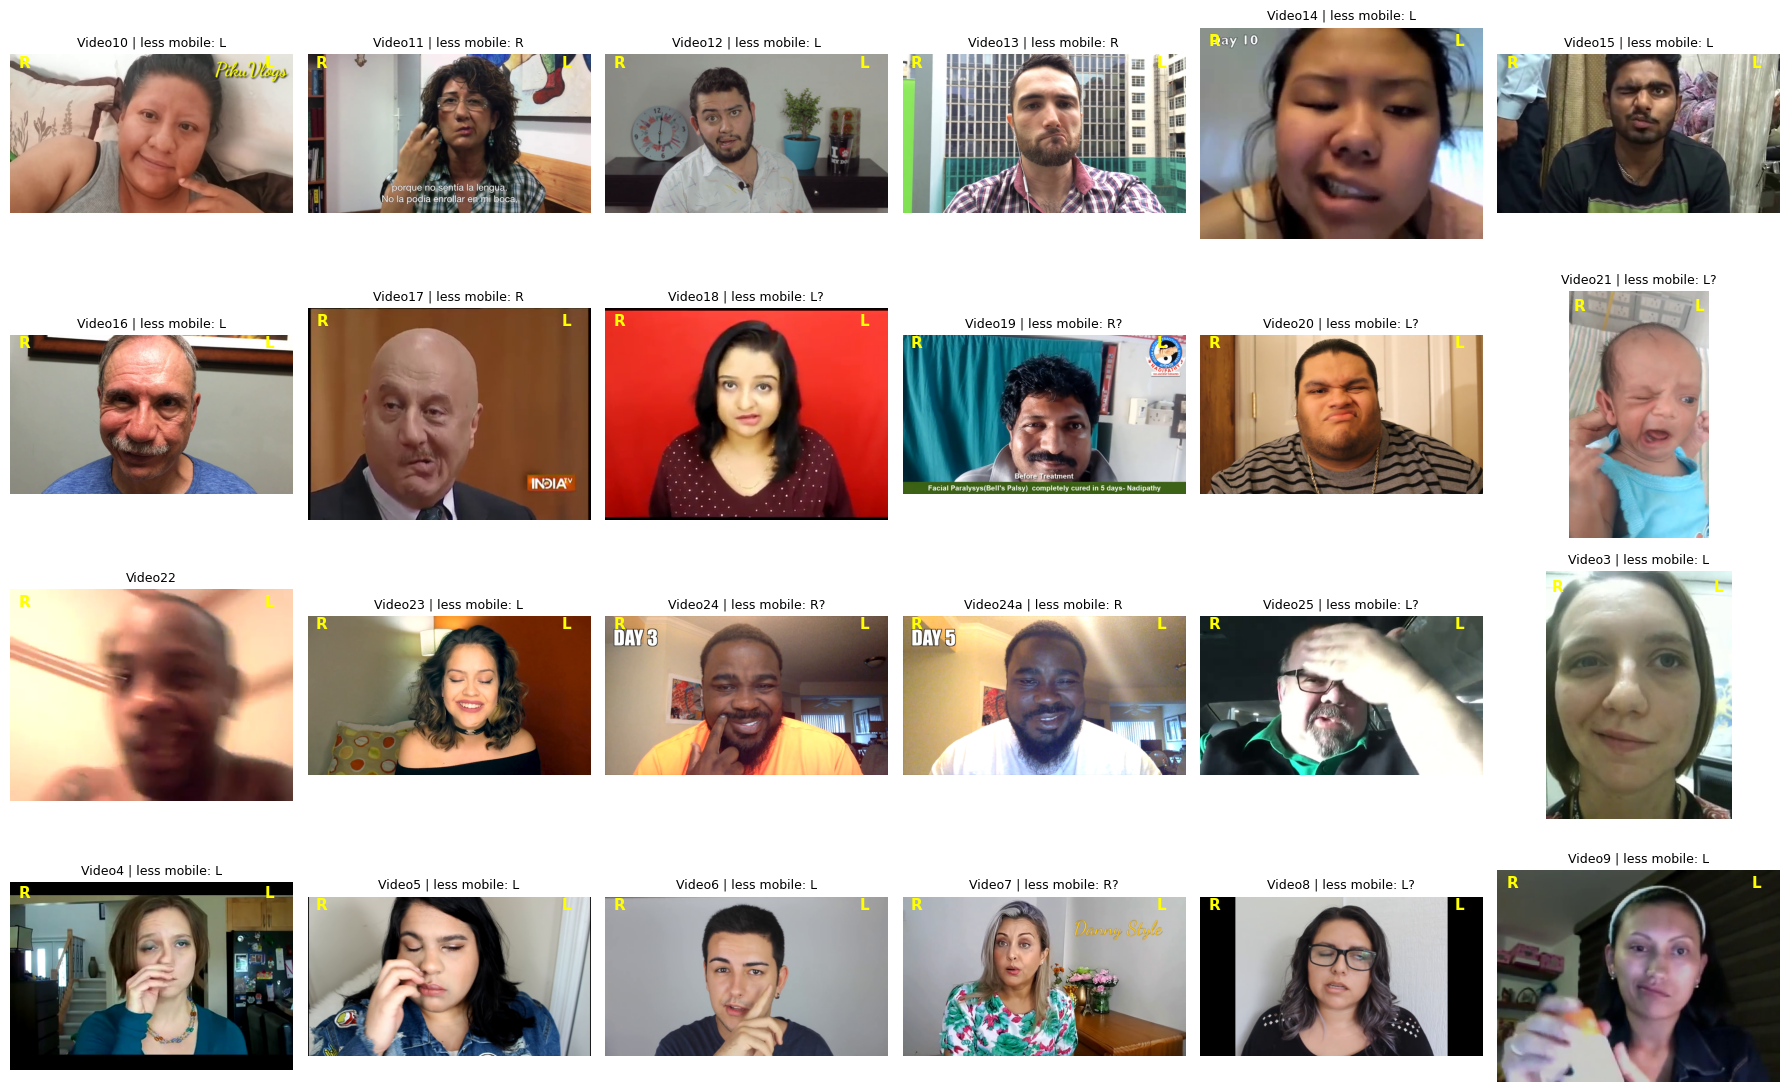

In [6]:
import math
_m = pd.read_csv(META, dtype=str).fillna('') if META.exists() else pd.DataFrame({'video_id': sorted(ff.video_id.unique()), 'palsy_side': ''})
if 'palsy_side' not in _m.columns: _m['palsy_side'] = ''
todo = _m[~_m.palsy_side.isin(['L', 'R', 'none'])].video_id.tolist()
def _rng(x): return np.percentile(x, 95) - np.percentile(x, 5)
print(len(todo), 'videos without a valid palsy_side')
rows = []
for v in todo:
    g = ff[ff.video_id == v]
    if len(g) < 10:
        rows.append(dict(video_id=v, n_frames=len(g), note='too few frames')); continue
    R = _rng(g.mouth_up_R) + _rng(g.brow_R); L = _rng(g.mouth_up_L) + _rng(g.brow_L)
    rows.append(dict(video_id=v, n_frames=len(g), R_move=R, L_move=L, asym_RL=(R - L) / (R + L + 1e-9),
                     less_mobile_side='L' if L < R else 'R', weak_signal=abs(R - L) / (R + L + 1e-9) < 0.10))
sug = pd.DataFrame(rows); display(sug.round(3))
sug.to_csv(OUT / 'side_suggestions_CHECK_ONLY.csv', index=False)
nc = 6; nr = max(1, math.ceil(len(todo) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(3 * nc, 2.8 * nr)); axs = np.atleast_1d(axs).ravel()
for ax in axs: ax.axis('off')
ll, rl = ('L', 'R') if MIRRORED else ('R', 'L')    # subject side shown on image left / right
for ax, v in zip(axs, todo):
    g = ff[ff.video_id == v]
    if len(g) == 0:
        ax.set_title(v + ' (no frames)', fontsize=9); continue
    img = cv2.imread(str(g.loc[(g.mouth_up_R + g.mouth_up_L).idxmax(), 'path']))
    if img is None:
        ax.set_title(v + ' (unreadable)', fontsize=9); continue
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); h, w = img.shape[:2]
    ax.text(0.03 * w, 0.08 * h, ll, color='yellow', fontsize=11, weight='bold')
    ax.text(0.90 * w, 0.08 * h, rl, color='yellow', fontsize=11, weight='bold')
    row = sug[sug.video_id == v]
    hint = ''
    if len(row) and 'less_mobile_side' in row and pd.notna(row.less_mobile_side.iloc[0]):
        hint = ' | less mobile: ' + row.less_mobile_side.iloc[0] + ('?' if row.weak_signal.iloc[0] else '')
    ax.set_title(v + hint, fontsize=9)
plt.tight_layout(); plt.show()

In [7]:
import re
meta = pd.read_csv(META, dtype=str).fillna('')
for c in ['patient_id', 'palsy_side', 'grade', 'visit']:
    if c not in meta.columns: meta[c] = ''

# Labels from the dataset authors: save them as ParFace_outputs/author_labels.csv with columns
#   video_id, palsy_side (L / R / none), and optionally patient_id, grade, visit.
# L means the SUBJECT's left. Nothing is guessed: videos without a label stay blank and are excluded later.
AUTH = OUT / 'author_labels.csv'
if AUTH.exists():
    a = pd.read_csv(AUTH, dtype=str).fillna('')
    a['palsy_side'] = (a['palsy_side'].str.strip().str.upper()
                       .map({'L': 'L', 'LEFT': 'L', 'R': 'R', 'RIGHT': 'R',
                             'NONE': 'none', 'CONTROL': 'none', 'HEALTHY': 'none'}).fillna(''))
    for col in ['palsy_side', 'patient_id', 'grade', 'visit']:
        if col in a.columns:
            m = a.set_index('video_id')[col]; m = m[m != '']
            meta.loc[meta.video_id.isin(m.index), col] = meta.video_id.map(m)
    print('merged labels from', AUTH.name)
else:
    print('No author_labels.csv yet: only the sides already in meta.csv are used.')

# same person -> same patient_id; default assumes a trailing letter is a repeat of the same person
# (e.g. Video24a = Video24). Confirm with the authors.
blank = meta.patient_id == ''
meta.loc[blank, 'patient_id'] = meta.loc[blank, 'video_id'].str.replace(r'[a-z]$', '', regex=True)
meta.to_csv(META, index=False)
print(meta.palsy_side.replace('', '(unlabeled)').value_counts().to_string())


No author_labels.csv yet: only the sides already in meta.csv are used.
palsy_side
(unlabeled)    24
L               3
R               1


### Video-level metrics
Per side: range of motion from the 5th-95th percentile spread, with the median as a neutral proxy for mouth up/down.

| feature | landmark proxy for |
|---|---|
| `brow` | frontalis (brow raise range) |
| `eye` | orbicularis oculi (aperture range, blink/closure) |
| `mouth_up` | zygomaticus (95th pct minus median) |
| `mouth_down` | depressor anguli oris (median minus 5th pct) |
| `mouth_out` | risorius / zygomaticus (lateral range) |

Compensation = healthy-side value above (mean + 1.5 SD) of the reference, clipped at 0.

In [8]:
FEATS  = ['brow', 'eye', 'mouth_up', 'mouth_down', 'mouth_out']
REGION = {'brow': 'frontalis', 'eye': 'orbicularis oculi', 'mouth_up': 'zygomaticus',
          'mouth_down': 'depressor anguli oris', 'mouth_out': 'risorius/zygomaticus'}
MIN_FRAMES = 15
ASYM_T = 0.15     # |asymmetry| below this counts as "symmetric" (arbitrary, tune on data)
def rng(x): return np.percentile(x, 95) - np.percentile(x, 5)

ffu = ff.copy()
if MIRRORED:
    swap = {}
    for b in ['mouth_up', 'mouth_out', 'brow', 'eye']:
        swap[f'{b}_R'], swap[f'{b}_L'] = f'{b}_L', f'{b}_R'
    ffu = ffu.rename(columns=swap)

rows = []
for vid, g in ffu.groupby('video_id'):
    if len(g) < MIN_FRAMES: continue
    r = dict(video_id=vid, n_frames=len(g))
    for s in 'RL':
        mu = g[f'mouth_up_{s}']
        r[f'brow_{s}'] = rng(g[f'brow_{s}'])
        r[f'eye_{s}'] = rng(g[f'eye_{s}'])
        r[f'mouth_up_{s}'] = np.percentile(mu, 95) - np.percentile(mu, 50)
        r[f'mouth_down_{s}'] = np.percentile(mu, 50) - np.percentile(mu, 5)
        r[f'mouth_out_{s}'] = rng(g[f'mouth_out_{s}'])
    rows.append(r)
V = pd.DataFrame(rows).merge(meta, on='video_id', how='inner')
for c in ['patient_id', 'palsy_side', 'grade', 'visit']:
    if c not in V.columns: V[c] = ''
V['visit_n'] = pd.to_numeric(V['visit'], errors='coerce')

# videos without a valid palsy_side are NOT analysed (a blank side would otherwise be treated as a palsy case)
_bad = sorted(V.loc[~V.palsy_side.isin(['L', 'R', 'none']), 'video_id'])
V = V[V.palsy_side.isin(['L', 'R', 'none'])].copy()
print(f'{len(V)} videos analysed; {len(_bad)} excluded for missing palsy_side')
assert len(V) > 0, 'No labelled videos. Fill palsy_side in meta.csv or author_labels.csv first.'

def split_sides(row, f):
    R, L = row[f'{f}_R'], row[f'{f}_L']
    if row.palsy_side == 'L': return R, L          # (healthy, palsy)
    if row.palsy_side == 'R': return L, R
    return max(R, L), min(R, L)                    # controls: no palsy side

has_ctrl = (V.palsy_side == 'none').any()
if has_ctrl:
    label = 'compensation vs. healthy norm (control videos)'
else:
    label = 'PROVISIONAL: norm built from healthy sides of palsy patients (circular, not a true healthy norm)'
print(label)

NORM, NORM_STATS = {}, {}
for f in FEATS:
    hp = V.apply(lambda r: split_sides(r, f), axis=1, result_type='expand')
    V[f'{f}_healthy'], V[f'{f}_palsy'] = hp[0], hp[1]
    signed = (V[f'{f}_healthy'] - V[f'{f}_palsy']) / (V[f'{f}_healthy'] + V[f'{f}_palsy'] + 1e-9)
    V[f'asym_{f}']  = signed                 # (healthy - palsy)/(healthy + palsy); negative = palsy side moves MORE
    V[f'aasym_{f}'] = signed.abs()
    # controls: max/min is >= 0 by construction, so use |R-L|/(R+L) for them to stay unbiased
    ctl = V.palsy_side == 'none'
    V.loc[ctl, f'aasym_{f}'] = ((V.loc[ctl, f'{f}_R'] - V.loc[ctl, f'{f}_L']).abs() /
                                (V.loc[ctl, f'{f}_R'] + V.loc[ctl, f'{f}_L'] + 1e-9))
    if has_ctrl:
        c = V[V.palsy_side == 'none']; pool = np.concatenate([c[f'{f}_R'], c[f'{f}_L']])
    else:
        pool = V.loc[V.palsy_side != 'none', f'{f}_healthy'].values
    thr = pool.mean() + 1.5 * pool.std(ddof=1)
    NORM[f] = thr
    NORM_STATS[f] = (pool.mean(), pool.std(ddof=1))
    V[f'comp_{f}'] = (V[f'{f}_healthy'] - thr).clip(lower=0)

def status(asym, comp, t=ASYM_T):
    if asym < -t:            return 'palsy side exceeds healthy (check synkinesis or side label)'
    sym, hi = abs(asym) < t, comp > 0
    if sym and not hi: return 'recovered (near reference)'
    if sym and hi:     return 'balance by overeffort: continue treatment'
    if not sym and hi: return 'overworking healthy side'
    return 'palsy-side deficit, no compensation'

for f in FEATS:
    V[f'status_{f}'] = [status(a, c) for a, c in zip(V[f'asym_{f}'], V[f'comp_{f}'])]

V.to_csv(OUT / 'video_features.csv', index=False)
pd.Series(NORM).rename('healthy_threshold_(mean+1.5SD, IPD units)').to_csv(OUT / 'norm_thresholds.csv')
display(V[['video_id', 'patient_id', 'palsy_side'] + [f'asym_{f}' for f in FEATS] + [f'comp_{f}' for f in FEATS]].round(3).head(25))

4 videos analysed; 23 excluded for missing palsy_side
PROVISIONAL: norm built from healthy sides of palsy patients (circular, not a true healthy norm)


,video_id,patient_id,palsy_side,asym_brow,asym_eye,asym_mouth_up,asym_mouth_down,asym_mouth_out,comp_brow,comp_eye,comp_mouth_up,comp_mouth_down,comp_mouth_out
0,Video1,P01,L,0.226,0.063,0.202,-0.094,0.188,0.0,0.0,0.0,0.0,0.0
11,Video1a,P01,L,0.178,0.233,0.282,-0.002,0.363,0.0,0.0,0.0,0.0,0.0
12,Video1b,P01,L,0.162,-0.019,-0.081,-0.036,0.265,0.0,0.0,0.0,0.0,0.0
13,Video2,P02,R,-0.436,-0.180,-0.180,-0.196,-0.240,0.0,0.0,0.0,0.0,0.0


### Longitudinal tracking (needs a `visit` column and 2+ visits per patient)
Per patient: a composite **asymmetry score** (mean |asymmetry|) and **compensation score** (mean compensation) per visit, change vs. the previous visit, and change vs. the patient's own best visit. Thresholds `D_ASYM` and `D_COMP` are arbitrary starting values.

In [9]:
D_ASYM, D_COMP = 0.03, 0.01
Vp = V[(V.palsy_side != 'none') & V.visit_n.notna()].copy()
Vp['asym_score'] = Vp[[f'aasym_{f}' for f in FEATS]].mean(axis=1)
Vp['comp_score'] = Vp[[f'comp_{f}' for f in FEATS]].mean(axis=1)

def long_status(da, dc, a, c):
    if a < ASYM_T and c == 0:         return 'recovered (both near reference)'
    if da < -D_ASYM and dc <= 0:      return 'true recovery (symmetry up, compensation down)'
    if da < -D_ASYM and dc > 0:       return 'balance by overeffort (symmetry up, compensation not down)'
    if abs(da) <= D_ASYM and dc > D_COMP: return 'overworking healthy side (symmetry flat, compensation rising)'
    return 'no clear change'

if len(Vp) and Vp.patient_id.value_counts().max() >= 2:
    Vp = Vp.sort_values(['patient_id', 'visit_n'])
    Vp['d_asym'] = Vp.groupby('patient_id').asym_score.diff()
    Vp['d_comp'] = Vp.groupby('patient_id').comp_score.diff()
    best = Vp.loc[Vp.groupby('patient_id').asym_score.idxmin(), ['patient_id', 'asym_score', 'comp_score']]
    Vp = Vp.merge(best.rename(columns={'asym_score': 'best_asym', 'comp_score': 'best_comp'}), on='patient_id')
    Vp['d_comp_vs_best'] = Vp.comp_score - Vp.best_comp
    Vp['trend'] = [long_status(da, dc, a, c) if pd.notna(da) else 'first visit'
                   for da, dc, a, c in zip(Vp.d_asym, Vp.d_comp, Vp.asym_score, Vp.comp_score)]
    display(Vp[['patient_id', 'visit_n', 'video_id', 'asym_score', 'comp_score', 'd_asym', 'd_comp', 'd_comp_vs_best', 'trend']].round(3))
    Vp.to_csv(OUT / 'longitudinal.csv', index=False)
else:
    print('No patient has 2+ visits with a numeric `visit` value in meta.csv; longitudinal step skipped.')

No patient has 2+ visits with a numeric `visit` value in meta.csv; longitudinal step skipped.


### Repeat-video reliability (ICC)
One-way ICC(1) of each feature across videos of the same patient. Only meaningful if those videos are repeat captures of the same task and visit. If they are different tasks or time points, low ICC is expected and says nothing about the method.

In [10]:
def icc1(df, col, grp):
    d = df[[grp, col]].dropna()
    g = d.groupby(grp)[col].agg(['mean', 'count', 'var'])
    g = g[g['count'] >= 2]
    a = len(g)
    if a < 2 or d[col].nunique() < 2: return np.nan
    N = g['count'].sum()
    gm = d[d[grp].isin(g.index)][col].mean()
    msb = (g['count'] * (g['mean'] - gm) ** 2).sum() / (a - 1)
    msw = ((g['count'] - 1) * g['var'].fillna(0)).sum() / (N - a)
    k0 = (N - (g['count'] ** 2).sum() / N) / (a - 1)
    den = msb + (k0 - 1) * msw
    return np.nan if den <= 1e-12 else (msb - msw) / den

pp = V[V.palsy_side != 'none']
n_rep = int((pp.patient_id.value_counts() >= 2).sum())
print('patients with 2+ videos:', n_rep, '| total palsy videos:', len(pp))
if n_rep < 2:
    print('ICC skipped: need at least 2 patients with repeat videos. Give videos of the same person the same patient_id.')
else:
    rel = {f'aasym_{f}': icc1(pp, f'aasym_{f}', 'patient_id') for f in FEATS}
    rel.update({f'comp_{f}': icc1(pp, f'comp_{f}', 'patient_id') for f in FEATS})
    print(pd.Series(rel).rename('ICC(1)').round(2).to_string())
    if n_rep < 5: print('Warning: fewer than 5 patients with repeats, so these ICCs are unstable.')
    print('Rough guide: <0.5 poor, 0.5-0.75 moderate, 0.75-0.9 good, >0.9 excellent.')

patients with 2+ videos: 1 | total palsy videos: 4
ICC skipped: need at least 2 patients with repeat videos. Give videos of the same person the same patient_id.


### Does compensation add information beyond symmetry?
- **Palsy vs. control** (needs control videos) and **grade regression** (needs ~20 graded palsy videos). Splits are by patient.
- The bootstrap resamples patients to give a confidence interval for the AUC difference. If it includes 0, there is no evidence compensation helps.
- Caveat: with control videos the healthy norm is computed on all controls before cross-validation, so palsy-vs-control AUC is slightly optimistic.

In [11]:
assert 'has_ctrl' in globals() and 'comp_brow' in V.columns, 'Run the video-level metrics cell successfully first.'
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, mean_absolute_error
from scipy.stats import spearmanr

A = [f'aasym_{f}' for f in FEATS]
C = [f'comp_{f}' for f in FEATS]
SETS = {'symmetry only': A, 'symmetry + compensation': A + C}
CLF = {'logistic': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000, class_weight='balanced')),
       'random forest': lambda: RandomForestClassifier(300, class_weight='balanced', min_samples_leaf=2, random_state=0)}
REG = {'ridge': lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
       'random forest': lambda: RandomForestRegressor(300, min_samples_leaf=2, random_state=0)}

def boot_delta(y, p0, p1, groups, n=500, seed=0):
    rg = np.random.default_rng(seed); ids = np.unique(groups); d = []
    where = {g: np.where(groups == g)[0] for g in ids}
    for _ in range(n):
        ii = np.concatenate([where[g] for g in rg.choice(ids, len(ids))])
        if len(set(y[ii])) < 2: continue
        d.append(roc_auc_score(y[ii], p1[ii]) - roc_auc_score(y[ii], p0[ii]))
    return np.percentile(d, [2.5, 50, 97.5]).round(3) if d else None

groups = V.patient_id.values
k = min(5, V.patient_id.nunique())
if has_ctrl and (V.palsy_side != 'none').any() and k >= 2:
    y = (V.palsy_side != 'none').astype(int).values
    print('--- palsy vs control ---')
    for mname, mk in CLF.items():
        P = {}
        for name, cols in SETS.items():
            P[name] = cross_val_predict(mk(), V[cols], y, groups=groups, cv=GroupKFold(k), method='predict_proba')[:, 1]
            print(f'{mname:14s} {name:26s} AUC={roc_auc_score(y, P[name]):.3f}')
        print(f'{mname:14s} delta AUC (comp added) 95% CI [low, median, high]:',
              boot_delta(y, P['symmetry only'], P['symmetry + compensation'], groups))
else:
    print('Palsy vs control skipped (needs control videos and 2+ patients).')

G = V[(V.palsy_side != 'none') & pd.to_numeric(V.grade, errors='coerce').notna()].copy()
if len(G) >= 20 and G.patient_id.nunique() >= 5:
    G['grade'] = G.grade.astype(float)
    print('--- grade regression ---')
    for mname, mk in REG.items():
        for name, cols in SETS.items():
            p = cross_val_predict(mk(), G[cols], G.grade, groups=G.patient_id.values,
                                  cv=GroupKFold(min(5, G.patient_id.nunique())))
            print(f'{mname:14s} {name:26s} MAE={mean_absolute_error(G.grade, p):.3f}  Spearman={spearmanr(G.grade, p)[0]:.3f}')
else:
    print('Not enough graded palsy videos for regression (need ~20+ videos from 5+ patients).')

Palsy vs control skipped (needs control videos and 2+ patients).
Not enough graded palsy videos for regression (need ~20+ videos from 5+ patients).


### Plots and plain-language report

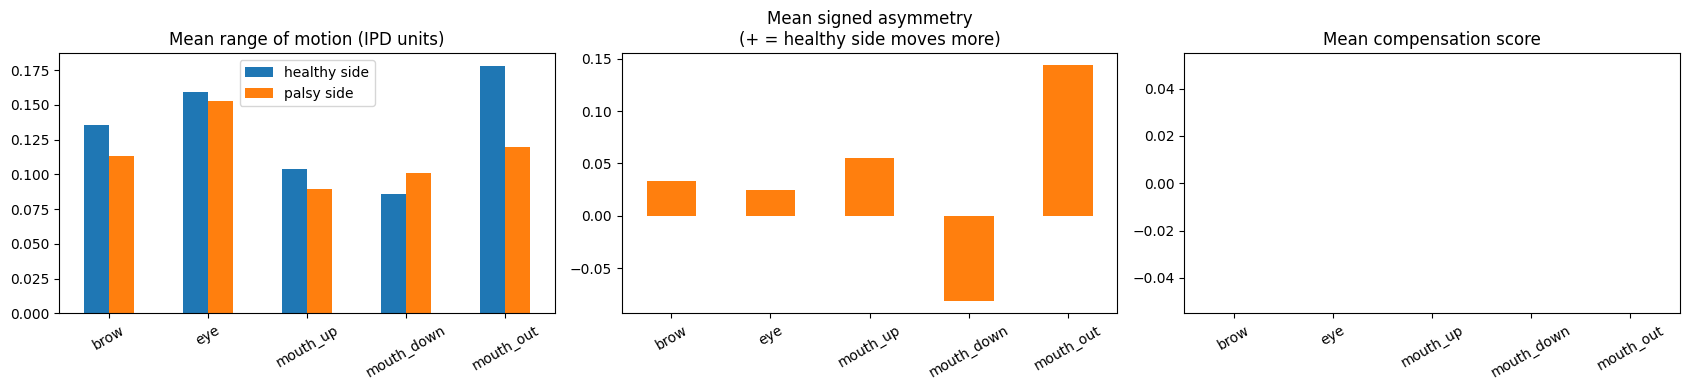

PROVISIONAL: norm built from healthy sides of palsy patients (circular, not a true healthy norm)
Video1 (P01, palsy side L):
  brow        [frontalis] asym=+0.23 comp=0.000 -> palsy-side deficit, no compensation
  eye         [orbicularis oculi] asym=+0.06 comp=0.000 -> recovered (near reference)
  mouth_up    [zygomaticus] asym=+0.20 comp=0.000 -> palsy-side deficit, no compensation
  mouth_down  [depressor anguli oris] asym=-0.09 comp=0.000 -> recovered (near reference)
  mouth_out   [risorius/zygomaticus] asym=+0.19 comp=0.000 -> palsy-side deficit, no compensation
Video1a (P01, palsy side L):
  brow        [frontalis] asym=+0.18 comp=0.000 -> palsy-side deficit, no compensation
  eye         [orbicularis oculi] asym=+0.23 comp=0.000 -> palsy-side deficit, no compensation
  mouth_up    [zygomaticus] asym=+0.28 comp=0.000 -> palsy-side deficit, no compensation
  mouth_down  [depressor anguli oris] asym=-0.00 comp=0.000 -> recovered (near reference)
  mouth_out   [risorius/zygomaticus

In [12]:
pv = V[V.palsy_side != 'none']
if len(pv):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    d = pd.DataFrame({'healthy side': [pv[f'{f}_healthy'].mean() for f in FEATS],
                      'palsy side':   [pv[f'{f}_palsy'].mean() for f in FEATS]}, index=FEATS)
    if has_ctrl:
        c = V[V.palsy_side == 'none']
        d['control (both sides)'] = [np.concatenate([c[f'{f}_R'], c[f'{f}_L']]).mean() for f in FEATS]
    d.plot.bar(ax=ax[0], rot=30, title='Mean range of motion (IPD units)')
    pv[[f'asym_{f}' for f in FEATS]].mean().rename(lambda s: s[5:]).plot.bar(ax=ax[1], rot=30, color='tab:orange',
        title='Mean signed asymmetry\n(+ = healthy side moves more)')
    pv[C].mean().rename(lambda s: s[5:]).plot.bar(ax=ax[2], rot=30, color='tab:red', title='Mean compensation score')
    plt.tight_layout(); plt.show()
print(label)

lines = []
for _, r in pv.iterrows():
    lines.append(f"{r.video_id} ({r.patient_id}, palsy side {r.palsy_side}):")
    for f in FEATS:
        lines.append(f"  {f:11s} [{REGION[f]}] asym={r[f'asym_{f}']:+.2f} comp={r[f'comp_{f}']:.3f} -> {r[f'status_{f}']}")
(OUT / 'report.txt').write_text('\n'.join(lines)); print('\n'.join(lines[:40]))

## Treatment planning: how much compensation, and what balance would take
For each region the notebook now states, in plain numbers:

1. **Healthy-side movement vs. the normal baseline.** Normal mean and upper limit (mean + 1.5 SD).
2. **Compensation** = healthy-side movement above that upper limit (in IPD units and approximate mm, assuming an adult IPD of 63 mm).
3. **Reduction to reach the normal baseline** = how much the healthy side would have to fall to sit at the normal mean.
4. **Reduction to reach full symmetry** = how much the healthy side would have to fall to match the palsy side.
5. A **what-if table**: projected asymmetry if the healthy side were weakened by 10-50%, assuming the palsy side does not change.

**How to read 3 vs. 4:** if the palsy side is weaker than normal, full symmetry needs the healthy side pushed *below* the normal range. The notebook flags this. Balance, not zero compensation, is the goal in the proposal, so the clinician chooses a point inside the range.

These are **movement-reduction estimates, not toxin doses**. Converting them to units per muscle needs the dose-response study in the proposal. With no control videos the baseline is provisional.

In [13]:
IPD_MM = 63.0   # approximate adult inter-pupillary distance; mm values are approximate
def mm(x): return float(x) * IPD_MM

def plan_table(r):
    rows = []
    for f in FEATS:
        h, p = r[f'{f}_healthy'], r[f'{f}_palsy']
        mu, sd = NORM_STATS[f]; lim = NORM[f]
        excess_mu = max(h - mu, 0)
        red_norm = excess_mu / h if h > 0 else 0
        red_sym  = max(h - p, 0) / h if h > 0 else 0
        lo, hi = sorted([red_norm, red_sym])
        if r[f'asym_{f}'] < -ASYM_T:
            note = 'palsy side exceeds healthy: no healthy-side weakening indicated (check synkinesis or side label)'
        elif red_sym > red_norm + 0.02:
            note = 'full symmetry would push the healthy side below normal; residual palsy-side deficit remains'
        elif r[f'comp_{f}'] == 0 and red_sym < 0.10:
            note = 'no meaningful excess; symmetric within tolerance'
        else:
            note = 'healthy-side excess; weakening range shown'
        rows.append(dict(feature=f, region=REGION[f], healthy=h, palsy=p, norm_mean=mu, norm_limit=lim,
                         comp=r[f'comp_{f}'], comp_pct_over_limit=100 * r[f'comp_{f}'] / lim if lim > 0 else np.nan,
                         excess_over_mean=excess_mu, pct_over_mean=100 * excess_mu / mu if mu > 0 else np.nan,
                         palsy_deficit=max(mu - p, 0), asym=r[f'asym_{f}'], status=r[f'status_{f}'],
                         red_to_norm_pct=100 * red_norm, red_to_sym_pct=100 * red_sym,
                         range_lo=100 * lo, range_hi=100 * hi, note=note))
    return pd.DataFrame(rows)

def whatif(h, p, pcts=(0, 10, 20, 30, 40, 50)):
    return {q: (h * (1 - q / 100) - p) / (h * (1 - q / 100) + p + 1e-9) for q in pcts}

pv = V[V.palsy_side != 'none']
ex = plan_table(pv.iloc[0]) if len(pv) else None
if ex is not None:
    print(pv.iloc[0].video_id, '|', label)
    show_cols = ['region', 'healthy', 'palsy', 'norm_mean', 'norm_limit', 'comp', 'comp_pct_over_limit',
                 'pct_over_mean', 'asym', 'red_to_norm_pct', 'red_to_sym_pct', 'note']
    display(ex[show_cols].round(3))

Video1 | PROVISIONAL: norm built from healthy sides of palsy patients (circular, not a true healthy norm)


,region,healthy,palsy,norm_mean,norm_limit,comp,comp_pct_over_limit,pct_over_mean,asym,red_to_norm_pct,red_to_sym_pct,note
0,frontalis,0.269,0.170,0.136,0.281,0.0,0.0,98.093,0.226,49.519,36.904,healthy-side excess; weakening range shown
1,orbicularis oculi,0.194,0.171,0.160,0.235,0.0,0.0,21.282,0.063,17.547,11.872,healthy-side excess; weakening range shown
2,zygomaticus,0.116,0.077,0.104,0.154,0.0,0.0,11.687,0.202,10.464,33.654,full symmetry would push the healthy side belo...
3,depressor anguli oris,0.062,0.075,0.086,0.126,0.0,0.0,0.000,-0.094,0.000,0.000,no meaningful excess; symmetric within tolerance
4,risorius/zygomaticus,0.160,0.109,0.178,0.312,0.0,0.0,0.000,0.188,0.000,31.635,full symmetry would push the healthy side belo...


## Follow-up check after treatment
Compares a patient's **first** and **latest** visit (or the pair you specify) and asks: did the healthy side fall as planned, and how far is the face from balance now? Confirm that treatment actually happened between the two visits.

In [14]:
PRE_POST = {}   # optional override, e.g. {'P03': ('Video5', 'Video6')} = (before, after)

def pick_pair(pid, g):
    if pid in PRE_POST:
        a, b = PRE_POST[pid]; return g[g.video_id == a].iloc[0], g[g.video_id == b].iloc[0]
    g = g[g.visit_n.notna()].sort_values('visit_n')
    if g.visit_n.nunique() >= 2: return g.iloc[0], g.iloc[-1]
    return None

def followup_table(pre, post):
    p0, p1 = plan_table(pre), plan_table(post)
    t = p0[['region', 'healthy', 'range_lo', 'range_hi', 'asym', 'comp']].rename(
        columns={'healthy': 'healthy_pre', 'range_lo': 'planned_lo', 'range_hi': 'planned_hi', 'asym': 'asym_pre', 'comp': 'comp_pre'})
    t['healthy_post'] = p1.healthy.values; t['asym_post'] = p1.asym.values; t['comp_post'] = p1.comp.values
    t['achieved_reduction_pct'] = 100 * (t.healthy_pre - t.healthy_post) / t.healthy_pre.replace(0, np.nan)
    t['residual_to_symmetry_pct'] = p1.red_to_sym_pct.values
    t['status_post'] = p1.status.values
    def verdict(r):
        if r.asym_post < -ASYM_T: return 'palsy side now exceeds healthy side: review'
        if abs(r.asym_post) < ASYM_T and r.comp_post == 0: return 'balanced (within tolerance, no compensation)'
        if r.achieved_reduction_pct < r.planned_lo - 5: return 'below planned reduction'
        if r.achieved_reduction_pct > r.planned_hi + 5: return 'beyond planned reduction (possible over-weakening)'
        return 'within planned range, balance not yet reached' if abs(r.asym_post) >= ASYM_T else 'within planned range'
    t['verdict'] = t.apply(verdict, axis=1)
    return t

pairs = {pid: pick_pair(pid, g) for pid, g in pv.groupby('patient_id')}
pairs = {k: v for k, v in pairs.items() if v is not None}
for pid, (a, b) in list(pairs.items())[:3]:
    print(pid, a.video_id, '->', b.video_id)
    display(followup_table(a, b).round(3))
if not pairs: print('No patient with 2 visits (or PRE_POST pair); follow-up section will be omitted from the clinical pages.')

No patient with 2 visits (or PRE_POST pair); follow-up section will be omitted from the clinical pages.


## One-page clinical summary (HTML, printable to PDF)
One page per patient: first visit (or the only video) as the baseline, the follow-up section if a second visit exists, bars showing healthy side vs. palsy side vs. the normal baseline, the compensation amount per region, the reduction range, the what-if table and the limits.

In [15]:
import html as _h
OUTP = OUT / 'clinical_pages'; OUTP.mkdir(exist_ok=True)

CSS = ('body{font-family:Arial,Helvetica,sans-serif;margin:28px;color:#1a1a1a;font-size:13px}'
       'h1{font-size:20px;margin:0 0 4px}h2{font-size:15px;margin:18px 0 6px;border-bottom:1px solid #ccc;padding-bottom:3px}'
       '.sub{color:#555;margin-bottom:10px}.warn{background:#fff4d6;border:1px solid #e6c15a;padding:8px;margin:8px 0}'
       'table{border-collapse:collapse;width:100%;margin:6px 0}th,td{border:1px solid #ccc;padding:4px 6px;text-align:left;vertical-align:top}'
       'th{background:#f0f0f0}.bar{position:relative;height:12px;background:#eee;margin:2px 0}'
       '.b{position:absolute;left:0;top:0;height:12px}.h{background:#d9534f}.p{background:#4a7fc1}'
       '.m{position:absolute;top:-3px;width:2px;height:18px;background:#000}.l{position:absolute;top:-3px;width:2px;height:18px;background:#e08a00}'
       '.leg span{margin-right:14px}.small{font-size:11px;color:#555}@media print{body{margin:10mm}}')

def f2(x, d=2): return 'n/a' if pd.isna(x) else f'{x:.{d}f}'

def bars_html(pt):
    top = max(pt[['healthy', 'palsy', 'norm_limit']].max()) * 1.15
    out = ''
    for _, r in pt.iterrows():
        w = lambda v: f'{100 * v / top:.1f}%'
        out += (f"<tr><td>{_h.escape(r.region)}</td><td style='width:55%'>"
                f"<div class='bar'><div class='b h' style='width:{w(r.healthy)}'></div>"
                f"<div class='m' style='left:{w(r.norm_mean)}'></div><div class='l' style='left:{w(r.norm_limit)}'></div></div>"
                f"<div class='bar'><div class='b p' style='width:{w(r.palsy)}'></div>"
                f"<div class='m' style='left:{w(r.norm_mean)}'></div><div class='l' style='left:{w(r.norm_limit)}'></div></div></td>"
                f"<td>{f2(mm(r.healthy), 1)} / {f2(mm(r.palsy), 1)} mm</td></tr>")
    return ("<div class='leg small'><span style='color:#d9534f'>&#9632; healthy side</span><span style='color:#4a7fc1'>&#9632; palsy side</span>"
            "<span>| black line = normal mean</span><span style='color:#e08a00'>| orange line = normal upper limit (mean + 1.5 SD)</span></div>"
            "<table><tr><th>Region</th><th>Movement range</th><th>Healthy / palsy</th></tr>" + out + '</table>')

def clinical_html(pid, pre, post=None):
    pt = plan_table(pre)
    rows = ''
    for _, r in pt.iterrows():
        comp_txt = (f"+{f2(mm(r.comp), 1)} mm ({f2(r.comp_pct_over_limit, 0)}% above normal limit)" if r.comp > 0 else 'none above normal limit')
        rows += (f"<tr><td>{_h.escape(r.region)}</td><td>{f2(mm(r.norm_mean), 1)} / {f2(mm(r.norm_limit), 1)} mm</td>"
                 f"<td>{comp_txt}<br><span class='small'>{f2(mm(r.excess_over_mean), 1)} mm ({f2(r.pct_over_mean, 0)}%) above normal mean</span></td>"
                 f"<td>{r.asym:+.2f}</td><td>{_h.escape(r.status)}</td>"
                 f"<td>{f2(r.red_to_norm_pct, 0)}% to normal<br>{f2(r.red_to_sym_pct, 0)}% to symmetry<br><b>range {f2(r.range_lo, 0)}-{f2(r.range_hi, 0)}%</b></td>"
                 f"<td class='small'>{_h.escape(r.note)}</td></tr>")
    wi = ''
    for _, r in pt.iterrows():
        a = whatif(r.healthy, r.palsy)
        wi += f"<tr><td>{_h.escape(r.region)}</td>" + ''.join(f'<td>{v:+.2f}</td>' for v in a.values()) + '</tr>'
    fu = ''
    if post is not None:
        t = followup_table(pre, post)
        fr = ''.join(f"<tr><td>{_h.escape(r.region)}</td><td>{f2(mm(r.healthy_pre), 1)} &rarr; {f2(mm(r.healthy_post), 1)} mm</td>"
                     f"<td>{f2(r.achieved_reduction_pct, 0)}% (planned {f2(r.planned_lo, 0)}-{f2(r.planned_hi, 0)}%)</td>"
                     f"<td>{r.asym_pre:+.2f} &rarr; {r.asym_post:+.2f}</td><td>{f2(mm(r.comp_pre), 1)} &rarr; {f2(mm(r.comp_post), 1)} mm</td>"
                     f"<td>{_h.escape(r.verdict)}</td></tr>" for _, r in t.iterrows())
        fu = (f"<h2>Follow-up: {_h.escape(pre.video_id)} &rarr; {_h.escape(post.video_id)}</h2>"
              "<p class='small'>Assumes treatment took place between these visits (confirm). Reduction = fall in healthy-side movement range.</p>"
              "<table><tr><th>Region</th><th>Healthy-side movement</th><th>Achieved reduction</th><th>Asymmetry</th><th>Compensation</th><th>Verdict</th></tr>" + fr + '</table>')
    warn = ('' if has_ctrl else "<div class='warn'><b>Provisional baseline.</b> No healthy-control videos were used, so the normal baseline is built from the healthy sides of palsy patients. Compensation is relative to that group, not to a true healthy norm.</div>")
    return ("<html><head><meta charset='utf-8'><title>Facial palsy compensation summary</title><style>" + CSS + "</style></head><body>"
            f"<h1>Facial palsy: compensation and balance summary</h1><div class='sub'>Patient {_h.escape(str(pid))} | video {_h.escape(pre.video_id)} | palsy side: {'left' if pre.palsy_side == 'L' else 'right'} (subject's own side) | {label}</div>"
            + warn + "<h2>1. Movement vs. normal baseline</h2>" + bars_html(pt) +
            "<h2>2. Compensation and what it would take to balance</h2>"
            "<table><tr><th>Region</th><th>Normal mean / limit</th><th>Healthy-side compensation</th><th>Asymmetry</th><th>Status</th><th>Healthy-side reduction needed</th><th>Note</th></tr>" + rows + '</table>'
            "<p class='small'>Asymmetry = (healthy - palsy) / (healthy + palsy); positive = healthy side moves more. Compensation = healthy-side movement above the normal upper limit. "
            "mm values are approximate (assumes 63 mm inter-pupillary distance).</p>"
            "<h2>3. What-if: projected asymmetry if the healthy side is weakened</h2><table><tr><th>Region</th>" + ''.join(f'<th>-{q}%</th>' for q in (0, 10, 20, 30, 40, 50)) + '</tr>' + wi + '</table>'
            "<p class='small'>Assumes the palsy side does not change. 0.00 = full symmetry. These are movement reductions, not toxin doses.</p>"
            + fu +
            "<h2>Limits</h2><ul class='small'><li>Landmark movement is a proxy for muscle activity. Platysma and synkinesis are not measured.</li>"
            "<li>The reduction range is not a dose. Dose-response is unvalidated and the final decision belongs to the treating clinician.</li>"
            "<li>Full symmetry may require weakening the healthy side below normal; balance, not zero compensation, is the intended target.</li>"
            "<li>Research prototype; not a diagnostic device and not validated against clinical grades.</li></ul></body></html>")

made = []
for pid, g in pv.groupby('patient_id'):
    pair = pairs.get(pid)
    pre, post = (pair if pair else (g.sort_values('visit_n').iloc[0], None))
    path = OUTP / f'clinical_page_{pid}.html'
    path.write_text(clinical_html(pid, pre, post), encoding='utf-8'); made.append(path)
print(len(made), 'clinical pages written to', OUTP)
if made:
    from IPython.display import HTML
    display(HTML(made[0].read_text(encoding='utf-8')))

2 clinical pages written to /content/drive/MyDrive/ParFace_outputs/clinical_pages
